# A Custom Text Classifier with Logistic Regression

Train a model to label sentences as positive or negative from 20 hand-written examples. Walkthrough of `src/analyze.py`.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import classification_report, accuracy_score
import analyze

pd.set_option('display.max_colwidth', 90)

## The data

In [2]:
df = analyze.load_data()
df['sentiment'].value_counts()

sentiment
positive    10
negative    10
Name: count, dtype: int64

In [3]:
df.head(6)

,text,sentiment
0,i love spending time with my friends and family,positive
1,that was the best meal i've ever had in my life,positive
2,i feel so grateful for everything i have in my life,positive
3,i received a promotion at work and i couldn't be happier,positive
4,watching a beautiful sunset always fills me with joy,positive
5,my partner surprised me with a thoughtful gift and it made my day,positive


## Features: bag of words

Each sentence becomes a row of word counts (see the vectorization project). The classifier learns one weight per word.

In [4]:
vec = CountVectorizer()
X = vec.fit_transform(df['text'])
print(X.shape[0], 'sentences x', X.shape[1], 'words')

20 sentences x 118 words


## Train and test

The pipeline bundles the vectorizer with the classifier, so the vocabulary is learned from the training sentences only. (Fitting the vectorizer on all the data before splitting lets test-set words leak into training.) The split is stratified, so both sets get equal numbers of positive and negative sentences.

In [5]:
X_train, X_test, y_train, y_test = analyze.split(df)
model = analyze.make_model().fit(X_train, y_train)
pred = model.predict(X_test)
pd.DataFrame({'text': X_test, 'actual': y_test, 'predicted': pred})

,text,actual,predicted
14,i have a headache and i feel terrible,negative,positive
8,i love the feeling of accomplishment after completing a challenging task,positive,negative
13,i got into an argument with my partner and we're not speaking,negative,positive
6,i am so proud of my daughter for graduating with honors,positive,positive
16,my car broke down and it's going to be expensive to fix,negative,positive
7,listening to my favorite music always puts me in a good mood,positive,positive


In [6]:
print(classification_report(y_test, pred, zero_division=0))

              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         3
    positive       0.40      0.67      0.50         3

    accuracy                           0.33         6
   macro avg       0.20      0.33      0.25         6
weighted avg       0.20      0.33      0.25         6



With a test set of 6 sentences, one wrong answer moves accuracy by 17 points, so this number says almost nothing. A better estimate is **repeated cross-validation**: train and test on many different splits and average.

In [7]:
cv = analyze.cross_validate(df)
cv.round(3)

,mean accuracy,std
features,,
Bag of Words,0.432,0.220
TF-IDF,0.405,0.239


Around 40% on a two-class problem with balanced classes is no better than a coin flip (and the standard deviation is large). The model has not learned to tell positive from negative.

## Why? Look at what it learned

Logistic regression gives each word a weight: positive pushes towards "positive", negative towards "negative".

In [8]:
final = analyze.make_model().fit(df['text'], df['sentiment'])
analyze.word_weights(final).round(2)

,negative word,weight,positive word,weight
0,because,-0.52,in,0.53
1,and,-0.32,me,0.52
2,feel,-0.27,love,0.43
3,responsibilities,-0.27,life,0.39
4,overwhelmed,-0.27,am,0.37
5,the,-0.25,of,0.35
6,terrible,-0.24,with,0.31
7,headache,-0.24,couldn,0.30
8,ticket,-0.22,promotion,0.30
9,ruined,-0.22,happier,0.30


Many of the heavy words are filler ("in", "me", "and", "because"). In 20 sentences each content word ("promotion", "headache") appears only once, so the model can't tell which words carry sentiment and latches onto whatever happens to separate the training examples. Words it hasn't seen carry no weight at all.

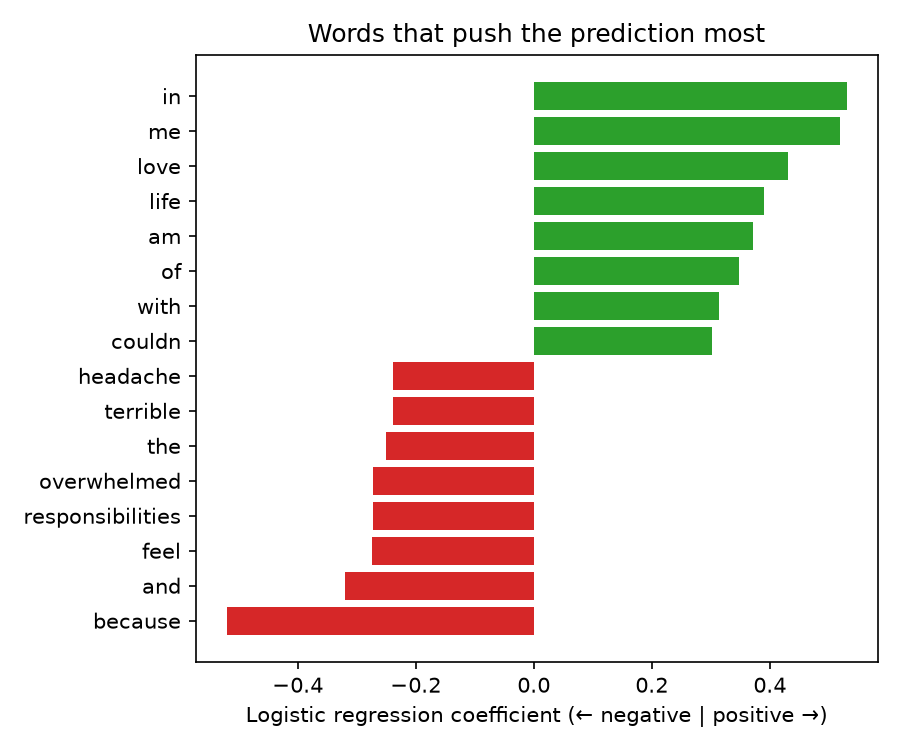

In [9]:
analyze.plot_weights(final)
from IPython.display import Image
Image('../outputs/word_weights.png', width=420)

## Predicting new sentences

In [10]:
analyze.predict_new(final, analyze.NEW_SENTENCES)

,sentence,prediction,confidence,P(positive)
0,"what a wonderful surprise, i am so happy",positive,0.55,0.55
1,this day has been absolutely terrible,negative,0.58,0.42
2,i lost my keys and missed the bus,negative,0.69,0.31
3,my team won the final and we celebrated all night,negative,0.72,0.28
4,i am not happy with how this went,positive,0.60,0.60
5,the meeting is at three o'clock,negative,0.56,0.44


Confidence stays between 0.5 and 0.7: the model is barely sure of anything. "My team won the final" comes out negative, and "I am not happy" positive. The first is overfitting to tiny data; the second is a limit of bag of words, which ignores word order and so can't see negation.

## Takeaways

- A classifier is only as good as its data: 20 examples can't teach a vocabulary.
- Never judge a model on a handful of test examples; use cross-validation.
- Fit the vectorizer inside the pipeline to avoid leakage.
- To improve: more labelled data, or pre-trained representations (word embeddings, a transformer) that already know "happy" and "joyful" are related.